## Preambule

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import pathlib
import pandas as pd
import xarray as xr
import matplotlib.font_manager as fm
from matplotlib.lines import Line2D
from matplotlib.patches import Polygon
import textwrap
from matplotlib.patches import Rectangle
import yaml

%load_ext autoreload
%autoreload all

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [14]:
import os
os.chdir(pathlib.Path("K:/Code/iam-fingerprints").resolve())
from src.globals import settings, paths
from src import (class_read_data,
                 class_indicators
                 )

In [15]:
font = 'Frutiger Lt Pro'
font_path = 'K:/Data/Fonts/'+font+'/'
font_files = [f for f in os.listdir(font_path) if os.path.isfile(os.path.join(font_path, f))]
for file in font_files:
    font_prop = fm.FontProperties(fname=font_path+file)
    fm.fontManager.addfont(font_path+file)
plt.rcParams['font.family'] = font_prop.get_name()

plt.rcParams.update({
    'font.size': 14,          # Default font size
    'axes.titlesize': 16,     # Plot title
    'axes.labelsize': 14,     # X and Y axis labels
    'xtick.labelsize': 12,    # X tick labels
    'ytick.labelsize': 12,    # Y tick labels
    'legend.fontsize': 12,    # Legend
    'figure.titlesize': 18    # Overall figure title
})

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge
from matplotlib.patches import Arc
from matplotlib.colors import Normalize
import matplotlib.patheffects as pe

effects = [
    pe.Stroke(linewidth=3, foreground='white'),
    pe.Normal()
]

## Read data

In [17]:
with open("src/globals/indicator_definitions.yaml", "r") as f:
    definitions = yaml.safe_load(f)
indicators = np.array(list(definitions['indicator'].keys())).astype(str)
names = np.array([np.array([definitions['indicator'][i]['name'] for i in indicators]).astype(str)])[0]
descriptions = np.array([np.array([definitions['indicator'][i]['description'] for i in indicators]).astype(str)])[0]
categories = np.array([np.array([definitions['indicator'][i]['category'] for i in indicators]).astype(str)])[0]

In [18]:
xr_diag = xr.open_dataset(paths.data / "xr_diag.nc")
xr_ind = xr.open_dataset(paths.data / "xr_ind.nc")

In [19]:
drop_models = ["FRIDA 3.1"]#, "MESSAGEix-GLOBIOM-GAINS 2.1-M-R12"]

In [20]:
xr_diag = xr_diag.drop_sel(model=drop_models)
xr_ind = xr_ind.drop_sel(model=drop_models)

## Plot

#### Timeline variable plots

(2010.0, 2061.0)

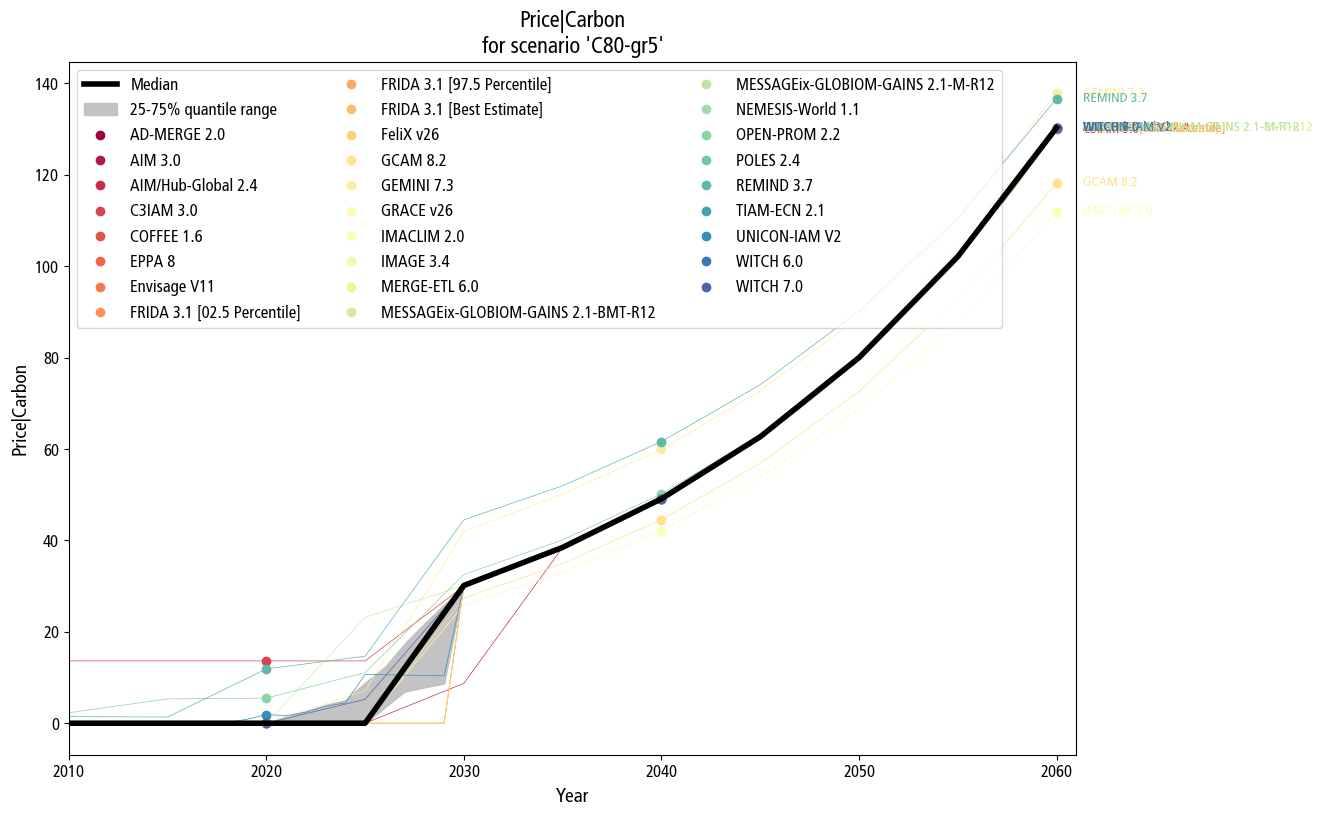

In [21]:
VAR = 'Price|Carbon'
SCEN = 'C80-gr5'

fig, ax = plt.subplots(figsize=(13, 9))

vals = np.array(xr_diag.sel(scenario=SCEN, region='World', variable=VAR, year = np.arange(2010, 2061)).value.median(dim='model'))
plt.plot(np.arange(2010, 2061), vals, label='Median', color='black', linewidth=4, zorder=1e9)

vals_q25 = np.array(xr_diag.sel(scenario=SCEN, region='World', variable=VAR, year = np.arange(2010, 2061)).value.quantile(0.25, dim='model'))
vals_q75 = np.array(xr_diag.sel(scenario=SCEN, region='World', variable=VAR, year = np.arange(2010, 2061)).value.quantile(0.75, dim='model'))
ax.fill_between(np.arange(2010, 2061), vals_q25, vals_q75, color='silver', alpha=0.95, label='25-75% quantile range', zorder=-1e8)
for mod_i, mod in enumerate(np.array(xr_ind.model)):
    color = plt.cm.Spectral(mod_i / len(xr_ind.model))
    vals = np.array(xr_diag.sel(model=mod, scenario=SCEN, region='World', variable=VAR, year = np.arange(2010, 2061)).value)
    plt.plot(np.arange(2010, 2061), vals, lw=0.5, c=color)
    ax.plot([2020, 2040, 2060], xr_diag.sel(model=mod, scenario=SCEN, region='World', variable=VAR, year = [2020, 2040, 2060]).value, 'o', c=color, label=mod)
    plt.annotate(mod, xy=(2061, vals[-1]), xytext=(5, 0), va='center', textcoords='offset points', fontsize=10, c=color)

if xr_diag.sel(scenario=SCEN, region='World', variable=VAR, year = np.arange(2010, 2061)).value.min() < 0:
    ax.axhline(y=0, color='silver', linewidth=1, linestyle='--')

plt.legend(ncol=3, loc='best')
ax.set_title(f"{VAR}\nfor scenario '{SCEN}'")
ax.set_ylabel(f"{VAR}")
ax.set_xlabel("Year")
ax.set_xlim([2010, 2061])

#### 2D indicator plots

posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values


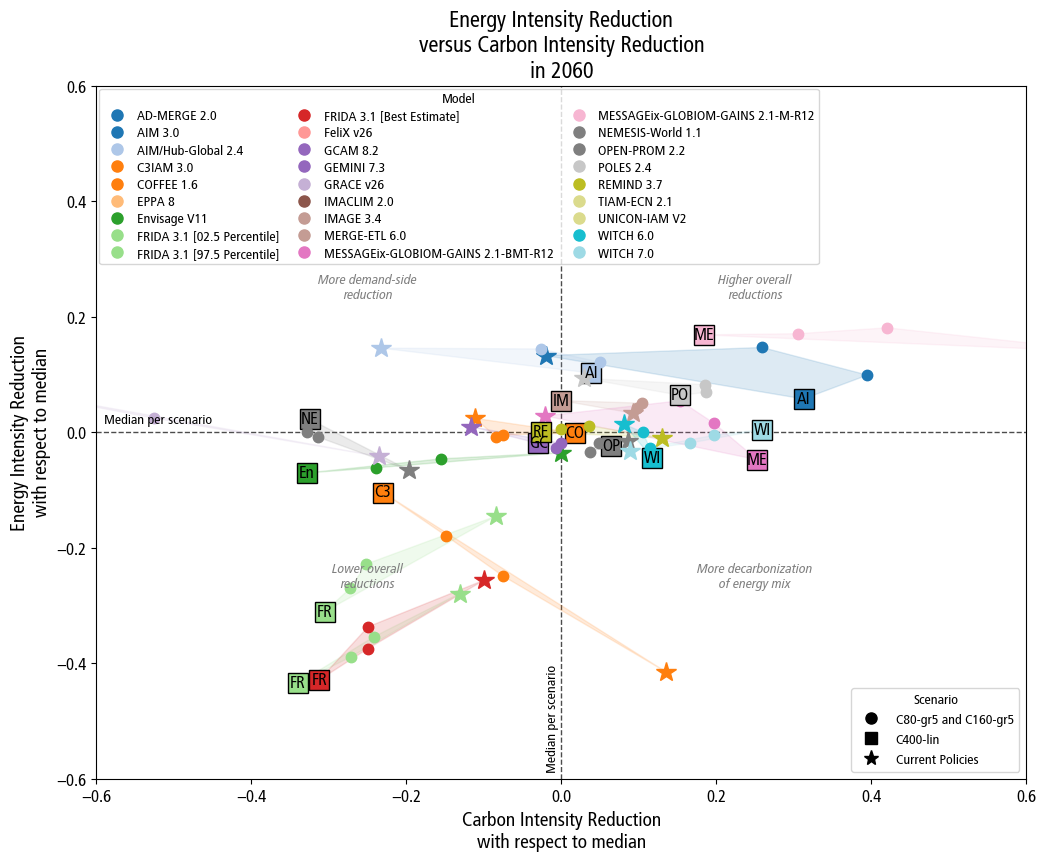

In [22]:
INDx = 'Carbon Intensity Reduction'
INDy = 'Energy Intensity Reduction'
YEAR = 2060


fig, ax = plt.subplots(figsize=(12, 9))

colors = []
for mod_i, mod in enumerate(xr_ind.model):
    color = plt.cm.tab20(mod_i / len(xr_ind.model))#[mod_i]
    colors.append(color)

    points = []

    short_name = f"{str(mod.values)[:]}"# {str(mod.values).split()[-1]}"

    for SCEN_i, SCEN in enumerate(['C400-lin', 'C80-gr5', 'C160-gr5', 'Current-Policies']):

        median_x = xr_ind.sel(scenario=SCEN, region='World', year=YEAR)[INDx].median(dim='model')
        median_y = xr_ind.sel(scenario=SCEN, region='World', year=YEAR)[INDy].median(dim='model')

        x = float(xr_ind.sel(model=mod, scenario=SCEN, region='World', year=YEAR)[INDx] - median_x)
        y = float(xr_ind.sel(model=mod, scenario=SCEN, region='World', year=YEAR)[INDy] - median_y)
        points.append((x, y))
        marker = '.'
        ec = color
        if SCEN == 'Current-Policies':
            marker = '*'
        if SCEN == 'C400-lin':
            marker = 's'
            ec = 'black'

        ax.plot(
            x, y,
            marker,
            color=color,
            markeredgecolor=ec,
            markersize=15,
            label=short_name if SCEN_i == 0 else None
        )
        if SCEN == 'C400-lin':
            if x > -0.6:
                ax.text(x, y, f"{str(mod.values)[:2]}", fontsize=12, va='center', ha='center', color='black')

    points = np.array(points, dtype=float)
    points = points[np.isfinite(points).all(axis=1)]

    # Plot average
    # if len(points) > 0:
    #     avg = points.mean(axis=0)
    #     ax.plot(avg[0], avg[1],
    #             marker='s', markersize=11,
    #             color=color, markeredgecolor='k', zorder=5)
    if len(points) == 2:
        ax.plot(points[:,0],points[:,1],
                color=color, lw=0.5, alpha=0.15, zorder=4)
    # Only draw if at least 3 valid points remain
    if len(points) >= 3:
        centroid = points.mean(axis=0)
        angles = np.arctan2(points[:,1] - centroid[1],
                            points[:,0] - centroid[0])
        points = points[np.argsort(angles)]

        ax.add_patch(Polygon(points,
                            closed=True,
                            facecolor=color,
                            edgecolor=color,
                            alpha=0.15))

# Legend
# Model legend (circles)
model_handles = [
    Line2D(
        [0], [0],
        marker='o',
        color=color,
        linestyle='None',
        markersize=8,
        label=str(mod.values)
    )
    for color, mod in zip(colors, xr_ind.model)
]

legend1 = ax.legend(
    handles=model_handles,
    title="Model",
    loc="upper left",
    ncol=3,
    fontsize=10,
    title_fontsize=10,
    columnspacing=0.8,
    handletextpad=0.4,
    labelspacing=0.3,
    borderpad=0.3,
    borderaxespad=0.2,
)

ax.add_artist(legend1)

scenario_handles = [
    Line2D([0], [0], marker='o', color='k', linestyle='None',
           markersize=8, label='C80-gr5 and C160-gr5'),
    Line2D([0], [0], marker='s', color='k', linestyle='None',
           markersize=8, label='C400-lin'),
    Line2D([0], [0], marker='*', color='k', linestyle='None',
           markersize=11, label='Current Policies'),
    # Line2D([0], [0], marker='s', color='k', markeredgecolor='k',
    #        linestyle='None', markersize=9, label='Model average'),
]

legend2 = ax.legend(
    handles=scenario_handles,
    title="Scenario",
    loc="lower right",
    fontsize=10,
    title_fontsize=10,
)

# Add horizontal line at 0
ax.axhline(0, color='black', linewidth=1, linestyle='--', alpha=0.7, zorder=-1e9)
ax.axvline(0, color='black', linewidth=1, linestyle='--', alpha=0.7, zorder=-1e9)
ax.text(-0.59, 0.01, 'Median per scenario', color='black', fontsize=10, va='bottom', ha='left')
ax.text(-0.02, -0.59, 'Median per scenario', color='black', rotation=90, fontsize=10, va='bottom', ha='left')
ax.text(-0.25, -0.25, 'Lower overall\nreductions', color='grey', fontsize=10, va='center', ha='center', fontstyle='italic')
ax.text(0.25, 0.25, 'Higher overall\nreductions', color='grey', fontsize=10, va='center', ha='center', fontstyle='italic')
ax.text(-0.25, 0.25, 'More demand-side\nreduction', color='grey', fontsize=10, va='center', ha='center', fontstyle='italic')
ax.text(0.25, -0.25, 'More decarbonization\nof energy mix', color='grey', fontsize=10, va='center', ha='center', fontstyle='italic')

ax.set_title(f"{INDy}\nversus {INDx}\nin {YEAR}")
ax.set_ylabel(f"{INDy}\nwith respect to median")
ax.set_xlabel(f"{INDx}\nwith respect to median")
ax.set_xlim([-0.6, 0.6])
ax.set_ylim([-0.6, 0.6])
plt.savefig(paths.figures_Xdrive / "2D planes" / "ei_ci.png", dpi=500, bbox_inches='tight')

#### By-indicator overview

In [23]:
for IND in names:
    YEAR = 2060

    models = xr_ind.model.values

    fig, ax = plt.subplots(figsize=(12, 9))

    vals = []
    for mod_i, mod in enumerate(models):
        color = plt.cm.tab20(mod_i / len(models))
        val = float(xr_ind.sel(region='World', year=YEAR, scenario='C400-lin')[IND].sel(model=mod))
        vals.append(val)
    
    rounding = 2
    if np.nanpercentile(np.abs(vals), 80) > 2:
        rounding = 1
        if np.nanpercentile(np.abs(vals), 80) > 10:
            rounding = 0

    # Now plot values for each model, sorted by val
    for mod_i, mod in enumerate(models[np.argsort(vals)]):
        val = float(xr_ind.sel(region='World', year=YEAR, scenario='C400-lin')[IND].sel(model=mod))
        if not np.isnan(val):
            if val > np.nanmedian(vals) + 4*np.nanstd(vals):
                val = np.percentile(vals, 90)
            if val < np.nanmedian(vals) - 4*np.nanstd(vals):
                val = np.percentile(vals, 10)
            ax.plot([val], [mod], 's', color='white', label='C400-lin',ms=0, mec='black')

    ax.axvline(0, color='black', linewidth=1, linestyle='--', alpha=0.7, zorder=-1e9)
    ax.set_ylim(ax.get_ylim())
    ax.fill_betweenx([-3, len(models)+5], xr_ind.sel(region='World', year=YEAR, scenario='C400-lin')[IND].quantile(0.25, dim='model'), xr_ind.sel(region='World', year=YEAR, scenario='C400-lin')[IND].quantile(0.75, dim='model'), color='silver', alpha=0.8, label='25-75% quantile range', zorder=-1e8)
    ax.axvline(xr_ind.sel(region='World', year=YEAR, scenario='C400-lin')[IND].median(dim='model'), color='black', linewidth=3, linestyle='-', zorder=-1)

    # Boxes
    scaled_width = 0.05*(ax.get_xlim()[1]-ax.get_xlim()[0])
    scaled_height = 0.035*(ax.get_ylim()[1]-ax.get_ylim()[0])
    idx = 0
    vals = np.array(vals)
    for mod_i, mod in enumerate(models[np.argsort(vals)]):
        #color = plt.cm.coolwarm(mod_i / len(models))
        val = float(xr_ind.sel(region='World', year=YEAR, scenario='C400-lin')[IND].sel(model=mod))
        if not np.isnan(val):
            color = plt.cm.coolwarm(idx / len(vals[~np.isnan(vals)]))
            idx += 1
            if np.abs(val) < np.nanmedian(vals) + 3*np.nanstd(vals):
                rect = Rectangle((val-scaled_width/2, mod_i-scaled_height/2), width=scaled_width, height=scaled_height, facecolor=color, edgecolor='black')
                ax.add_patch(rect)
                ax.text(val, mod_i, f"{val:.{rounding}f}", fontsize=14, va='center', ha='center', color='black')

    # Median
    val_med = float(xr_ind.sel(region='World', year=YEAR, scenario='C400-lin')[IND].median(dim='model'))
    rect = Rectangle((val_med-scaled_width/2, -1-scaled_height/2), width=scaled_width, height=scaled_height, facecolor='white', edgecolor='black')
    ax.add_patch(rect)
    ax.text(val_med, -1, f"{val_med:.{rounding}f}", fontsize=14, va='center', ha='center', color='black')

    ax.grid(linestyle='--', alpha=0.5, zorder=-1e9)
    ax.set_ylim([-1.5, ax.get_ylim()[1]])

    ax.set_title(f"{IND}\n")
    ax.text(0.5, 1.02, descriptions[np.where(names == IND)[0][0]], transform=ax.transAxes, fontsize=12, ha='center', fontstyle='italic')

    # Set tick size
    ax.tick_params(axis='both', which='major', labelsize=15)

    fig.savefig(paths.figures_Xdrive / "By_indicator" / f"{IND.replace('|','_')}.png", dpi=500, bbox_inches='tight')
    plt.close()

#### Fingerprint

In [24]:
xr_diag_for_fingerprint = xr_diag.drop_sel(model=['TIAM-ECN 2.1'])
xr_ind_for_fingerprint = xr_ind.drop_sel(model=['TIAM-ECN 2.1'])
medians = xr_ind_for_fingerprint.sel(region='World', year=2060).median(dim='model')
maxima = xr_ind_for_fingerprint.sel(region='World', year=2060).median(dim='model') + 2*xr_ind_for_fingerprint.sel(region='World', year=2060).std(dim='model')
minima = xr_ind_for_fingerprint.sel(region='World', year=2060).median(dim='model') - 2*xr_ind_for_fingerprint.sel(region='World', year=2060).std(dim='model')
model_specific = xr_ind.sel(region='World', year=2060).copy()
dev = (model_specific - medians) / (maxima - minima)+0.5
cmaps = [plt.cm.Reds,plt.cm.Blues,plt.cm.Greens,plt.cm.YlOrBr,plt.cm.Purples]
n = len(names)
start_angle = 90
angles = np.linspace(start_angle, start_angle + 360, n + 1)
norm = Normalize(vmin=-0.2, vmax=0.8)

In [25]:
for MODEL in np.array(xr_ind.model):
    cumulative_indicators = 0
    fig, ax = plt.subplots(figsize=(8, 8))
    for cat_i, cat in enumerate(np.unique(categories)):
        inds_in_cat = names[np.where(categories == cat)[0]][::-1]
        cat_color = ['tomato', 'steelblue', 'forestgreen', 'goldenrod', 'darkviolet'][cat_i]
        for ind_i, ind in enumerate(inds_in_cat):
            # Wedge
            r0 = np.max([np.nanmin(dev.sel(model=MODEL)[ind].values), 0])
            r1 = np.min([1, np.nanmax(dev.sel(model=MODEL)[ind].values)])
            theta_start = angles[cumulative_indicators + ind_i]
            theta_end = angles[cumulative_indicators + ind_i + 1]
            cmap = cmaps[cat_i]
            n_layers = 50
            radii = np.linspace(r0, r1, n_layers + 1)
            for j in range(n_layers):
                wedge = Wedge(
                    center=(0, 0),
                    r=radii[j + 1],
                    theta1=theta_start+1,
                    theta2=theta_end-1,
                    width=radii[j + 1] - radii[j],
                    facecolor=cmap(norm((radii[j] + radii[j + 1]) / 2)),
                    edgecolor='none',
                )
                ax.add_patch(wedge)

            # Scenario indicators
            for scen_i, scen in enumerate(np.array(xr_ind.scenario)):
                r_scen = float(dev.sel(model=MODEL, scenario=scen)[ind].values)
                col = 'black'
                lw = 0.5
                if scen == 'C400-lin':
                    col = 'black'
                    lw = 5
                if not np.isnan(r_scen) and r_scen > 0 and r_scen < 1:
                    theta_start = angles[cumulative_indicators + ind_i]
                    theta_end = angles[cumulative_indicators + ind_i + 1]

                    arc = Arc(
                        (0, 0),
                        width=2 * r_scen,
                        height=2 * r_scen,
                        theta1=theta_start+2,
                        theta2=theta_end-2,
                        color=col,
                        linewidth=lw,
                    )
                    ax.add_patch(arc)

            # Annotations
            r_annotation = 1.1
            theta_annotation = (angles[cumulative_indicators+ind_i] + angles[cumulative_indicators+ind_i + 1]) / 2
            x_annotation = r_annotation * np.cos(np.radians(theta_annotation))
            y_annotation = r_annotation * np.sin(np.radians(theta_annotation))
            ax.text(
                x_annotation, y_annotation, ind.replace(" ", "\n"),
                ha='center', va='center',
                rotation=0, #theta_annotation - 90 if theta_annotation > 0 and theta_annotation < 180 else theta_annotation + 90,
                rotation_mode='anchor',
                fontsize=10, path_effects=effects
            )

            # Add grid
            ax.plot([0, np.cos(np.radians(angles[cumulative_indicators+ind_i]))],
                    [0, np.sin(np.radians(angles[cumulative_indicators+ind_i]))], color='silver', linewidth=0.25, zorder=-1e9)
            ax.add_artist(plt.Circle((0, 0), 1, color='silver', fill=False, linewidth=1, zorder=-1e9))
            ax.add_artist(plt.Circle((0, 0), 0.5, color='black', fill=False, linewidth=1, zorder=1e9))
            ax.add_artist(plt.Circle((0, 0), 0.25, color='silver', fill=False, linewidth=0.1, zorder=-1e9))
            ax.add_artist(plt.Circle((0, 0), 0.75, color='silver', fill=False, linewidth=0.1, zorder=-1e9))
        cumulative_indicators += len(inds_in_cat)

    # Indicate eta symbol in inner circle
    ax.text(0, 0.5, r'$\eta_s$', fontsize=10, ha='center', va='center', color='black', path_effects=effects, zorder=1e10)
    ax.text(0, 0, r'$\eta_s - 2\sigma_s$', fontsize=10, ha='center', va='center', color='black', path_effects=effects, zorder=1e10)
    ax.text(0, 1, r'$\eta_s + 2\sigma_s$', fontsize=10, ha='center', va='center', color='black', path_effects=effects, zorder=1e10)

    # add legend on the meaning of eta and sigma
    ax.text(-1.3, -1.25, r'$\eta_s$ = median across models, per scenario s', fontsize=10, ha='left', va='center', color='black')
    ax.text(-1.3, -1.3, r'$\sigma_s$ = standard deviation across models, per scenario s', fontsize=10, ha='left', va='center', color='black')

    # Add category names and arcs
    cumulative_indicators = 0
    for cat_i, cat in enumerate(np.unique(categories)):
        cat_color = ['tomato', 'steelblue', 'forestgreen', 'goldenrod', 'darkviolet'][cat_i]
        inds_in_cat = names[np.where(categories == cat)[0]][::-1]
        theta_start = angles[cumulative_indicators]
        theta_end = angles[cumulative_indicators + len(inds_in_cat)]
        theta_mid = (theta_start + theta_end) / 2
        x_text = 1.3 * np.cos(np.radians(theta_mid))
        y_text = 1.3 * np.sin(np.radians(theta_mid))
        ax.text(x_text, y_text, cat.replace(" ", "\n"), ha='center', va='center', fontsize=12, fontweight='bold', color=cat_color)

        arc = Arc((0, 0),width=2.,height=2,theta1=theta_start+2,theta2=theta_end-2,color=cat_color,linewidth=6)
        ax.add_patch(arc)

        cumulative_indicators += len(inds_in_cat)

    # Formatting
    ax.set_aspect("equal")
    ax.set_xlim(-1.1, 1.1)
    ax.set_ylim(-1.1, 1.1)
    ax.axis("off")
    ax.set_title(f"{MODEL}\n\n", fontsize=20)

    fig.savefig(paths.figures_Xdrive / "fingerprints" / f"{MODEL.replace("/", " ")}.png", dpi=500, bbox_inches='tight')
    plt.close()

C:\Users\dekkerm\AppData\Local\Temp\2\ipykernel_11164\597012807.py:9: RuntimeWarning: All-NaN slice encountered
  r0 = np.max([np.nanmin(dev.sel(model=MODEL)[ind].values), 0])
C:\Users\dekkerm\AppData\Local\Temp\2\ipykernel_11164\597012807.py:10: RuntimeWarning: All-NaN slice encountered
  r1 = np.min([1, np.nanmax(dev.sel(model=MODEL)[ind].values)])
